# Exploratory Data Analysis (EDA): SemEval-2020 Task 9 (SentiMix Hindi-English)

## Overview
This notebook performs a comprehensive **Exploratory Data Analysis (EDA)** on the processed Hindi-English code-mixed dataset from **SemEval-2020 Task 9 (SentiMix)**.

### Objectives:
1. **Dataset Size & Structure**: Verify sample counts across `train`, `dev`, and `test` splits.
2. **Class Distribution**: Quantify sentiment distributions (`positive`, `negative`, `neutral`) and evaluate class balance.
3. **Text Length Analysis**: Compute summary statistics for word count and character count per tweet.
4. **Length Distributions**: Visualize KDE density curves and sentiment-stratified boxplots.
5. **Vocabulary & Out-of-Vocabulary (OOV)**: Assess unique vocabulary size and out-of-vocabulary rates across splits.
6. **Token Frequency Analysis**: Identify dominant lexical tokens overall and across sentiment categories.
7. **Linguistic & Code-Mixing Traits**: Measure prevalence of social media markers (@mentions, URLs, emojis, character elongation).
8. **Qualitative Inspection**: Examine representative examples from each sentiment class.


## 1. Setup and Environment Configuration

In [1]:
import os
import re
import sys
import string
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print("Environment configured successfully.")


Environment configured successfully.


## 2. Load Processed Datasets

In [2]:
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_dir = project_root / "data" / "processed"

print(f"Loading datasets from: {processed_dir.resolve()}")

train_df = pd.read_csv(processed_dir / "train.csv", dtype={"uid": str, "text": str, "sentiment": str})
dev_df = pd.read_csv(processed_dir / "dev.csv", dtype={"uid": str, "text": str, "sentiment": str})
test_df = pd.read_csv(processed_dir / "test.csv", dtype={"uid": str, "text": str, "sentiment": str})

for df in [train_df, dev_df, test_df]:
    df["text"] = df["text"].fillna("")
    df["word_count"] = df["text"].apply(lambda t: len(t.split()))
    df["char_count"] = df["text"].apply(len)

splits = {"Train": train_df, "Dev": dev_df, "Test": test_df}

print(f"Train Shape: {train_df.shape}")
print(f"Dev Shape:   {dev_df.shape}")
print(f"Test Shape:  {test_df.shape}")


Loading datasets from: C:\Users\Danish ahmad\.gemini\antigravity-ide\scratch\NLP_Noise_Robustness\data\processed
Train Shape: (14000, 5)
Dev Shape:   (3000, 5)
Test Shape:  (3000, 5)


## 3. Data Integrity & Sample Counts

In [3]:
integrity_summary = []
total_all = len(train_df) + len(dev_df) + len(test_df)

for name, df in splits.items():
    pct = (len(df) / total_all) * 100
    integrity_summary.append({
        "Split": name,
        "Total Samples": len(df),
        "Missing UIDs": df["uid"].isnull().sum(),
        "Missing Texts": (df["text"].str.strip() == "").sum(),
        "Missing Sentiments": df["sentiment"].isnull().sum(),
        "Duplicate UIDs": df["uid"].duplicated().sum(),
        "Duplicate Texts": df["text"].duplicated().sum(),
        "% of Total Corpus": f"{pct:.1f}%"
    })

integrity_df = pd.DataFrame(integrity_summary).set_index("Split")
display(integrity_df)


,Total Samples,Missing UIDs,Missing Texts,Missing Sentiments,Duplicate UIDs,Duplicate Texts,% of Total Corpus
Split,,,,,,,
Train,14000,0,0,0,0,1,70.0%
Dev,3000,0,0,0,0,0,15.0%
Test,3000,0,0,0,0,0,15.0%


## 4. Class Distribution and Balance

In [4]:
class_records = []
for name, df in splits.items():
    vc = df["sentiment"].value_counts()
    tot = len(df)
    neu_pct = (vc.get("neutral", 0) / tot) * 100
    pos_pct = (vc.get("positive", 0) / tot) * 100
    neg_pct = (vc.get("negative", 0) / tot) * 100
    class_records.append({
        "Split": name,
        "Neutral (Count)": vc.get("neutral", 0),
        "Neutral (%)": f"{neu_pct:.2f}%",
        "Positive (Count)": vc.get("positive", 0),
        "Positive (%)": f"{pos_pct:.2f}%",
        "Negative (Count)": vc.get("negative", 0),
        "Negative (%)": f"{neg_pct:.2f}%",
        "Total": tot
    })

class_df = pd.DataFrame(class_records).set_index("Split")
display(class_df)


,Neutral (Count),Neutral (%),Positive (Count),Positive (%),Negative (Count),Negative (%),Total
Split,,,,,,,
Train,5264,37.60%,4634,33.10%,4102,29.30%,14000
Dev,1128,37.60%,982,32.73%,890,29.67%,3000
Test,1100,36.67%,1000,33.33%,900,30.00%,3000


findfont: Failed to find font weight semibold for Arial, now using 700.


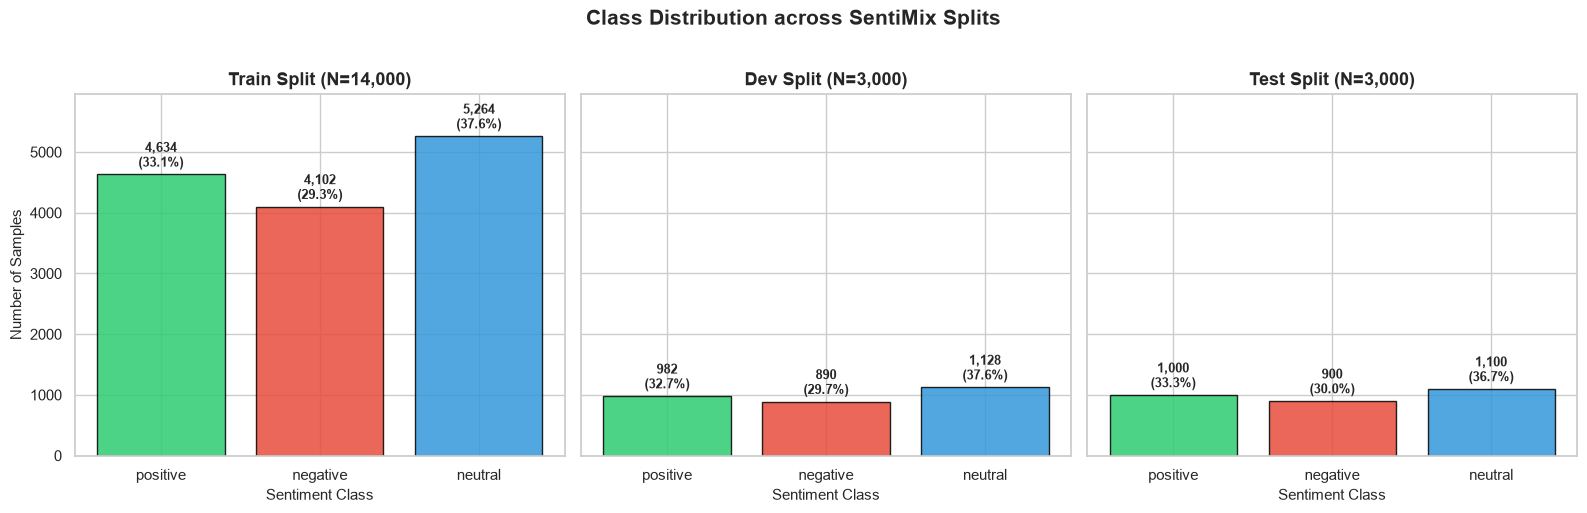

In [5]:
palette = {"positive": "#2ecc71", "negative": "#e74c3c", "neutral": "#3498db"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for idx, (name, df) in enumerate(splits.items()):
    ax = axes[idx]
    counts = df["sentiment"].value_counts()[["positive", "negative", "neutral"]]
    percentages = (counts / len(df)) * 100
    bars = ax.bar(
        counts.index,
        counts.values,
        color=[palette[k] for k in counts.index],
        edgecolor="black",
        alpha=0.85
    )
    ax.set_title(f"{name} Split (N={len(df):,})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Sentiment Class", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Number of Samples", fontsize=11)

    for bar, count, pct in zip(bars, counts.values, percentages.values):
        yval = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            yval + 60,
            f"{count:,}\n({pct:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="semibold"
        )
    ax.set_ylim(0, max(df["sentiment"].value_counts().max() for df in splits.values()) + 700)

plt.suptitle("Class Distribution across SentiMix Splits", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 5. Text Length Statistics (Word & Character Counts)

In [6]:
def length_summary(df, col):
    s = df[col]
    return {
        "Min": int(s.min()),
        "Max": int(s.max()),
        "Mean": round(float(s.mean()), 2),
        "Median": round(float(s.median()), 1),
        "Std Dev": round(float(s.std()), 2),
        "25th Pct": round(float(s.quantile(0.25)), 1),
        "75th Pct": round(float(s.quantile(0.75)), 1),
        "95th Pct": round(float(s.quantile(0.95)), 1)
    }

length_metrics = []
for name, df in splits.items():
    w_stats = length_summary(df, "word_count")
    c_stats = length_summary(df, "char_count")
    w_stats["Split"] = f"{name} (Words)"
    c_stats["Split"] = f"{name} (Chars)"
    length_metrics.extend([w_stats, c_stats])

length_df = pd.DataFrame(length_metrics).set_index("Split")
display(length_df)


,Min,Max,Mean,Median,Std Dev,25th Pct,75th Pct,95th Pct
Split,,,,,,,,
Train (Words),1,56,26.11,28.0,6.35,22.0,31.0,34.0
Train (Chars),5,179,127.02,142.0,27.82,111.0,147.0,151.0
Dev (Words),8,44,26.23,28.0,6.26,22.0,31.0,34.0
Dev (Chars),35,163,127.69,142.0,27.45,114.0,147.0,151.0
Test (Words),8,41,26.12,28.0,6.31,22.0,31.0,34.0
Test (Chars),34,212,129.90,144.0,28.59,113.0,149.0,155.0


In [7]:
cls_metrics = []
for s_class in ["neutral", "positive", "negative"]:
    sub = train_df[train_df["sentiment"] == s_class]
    w_s = length_summary(sub, "word_count")
    c_s = length_summary(sub, "char_count")
    w_s["Sentiment Class"] = f"{s_class.capitalize()} (Words)"
    c_s["Sentiment Class"] = f"{s_class.capitalize()} (Chars)"
    cls_metrics.extend([w_s, c_s])

cls_length_df = pd.DataFrame(cls_metrics).set_index("Sentiment Class")
display(cls_length_df)


,Min,Max,Mean,Median,Std Dev,25th Pct,75th Pct,95th Pct
Sentiment Class,,,,,,,,
Neutral (Words),1,56,25.75,28.0,6.67,21.0,31.0,34.0
Neutral (Chars),5,179,124.70,141.0,29.76,105.0,147.0,151.0
Positive (Words),8,45,25.69,27.0,6.34,22.0,30.0,34.0
Positive (Chars),32,174,126.01,141.0,28.01,111.0,146.0,150.0
Negative (Words),8,42,27.04,29.0,5.84,24.0,31.0,34.0
Negative (Chars),37,162,131.15,143.0,24.37,120.0,147.0,151.0


### Text Length Distribution Plots

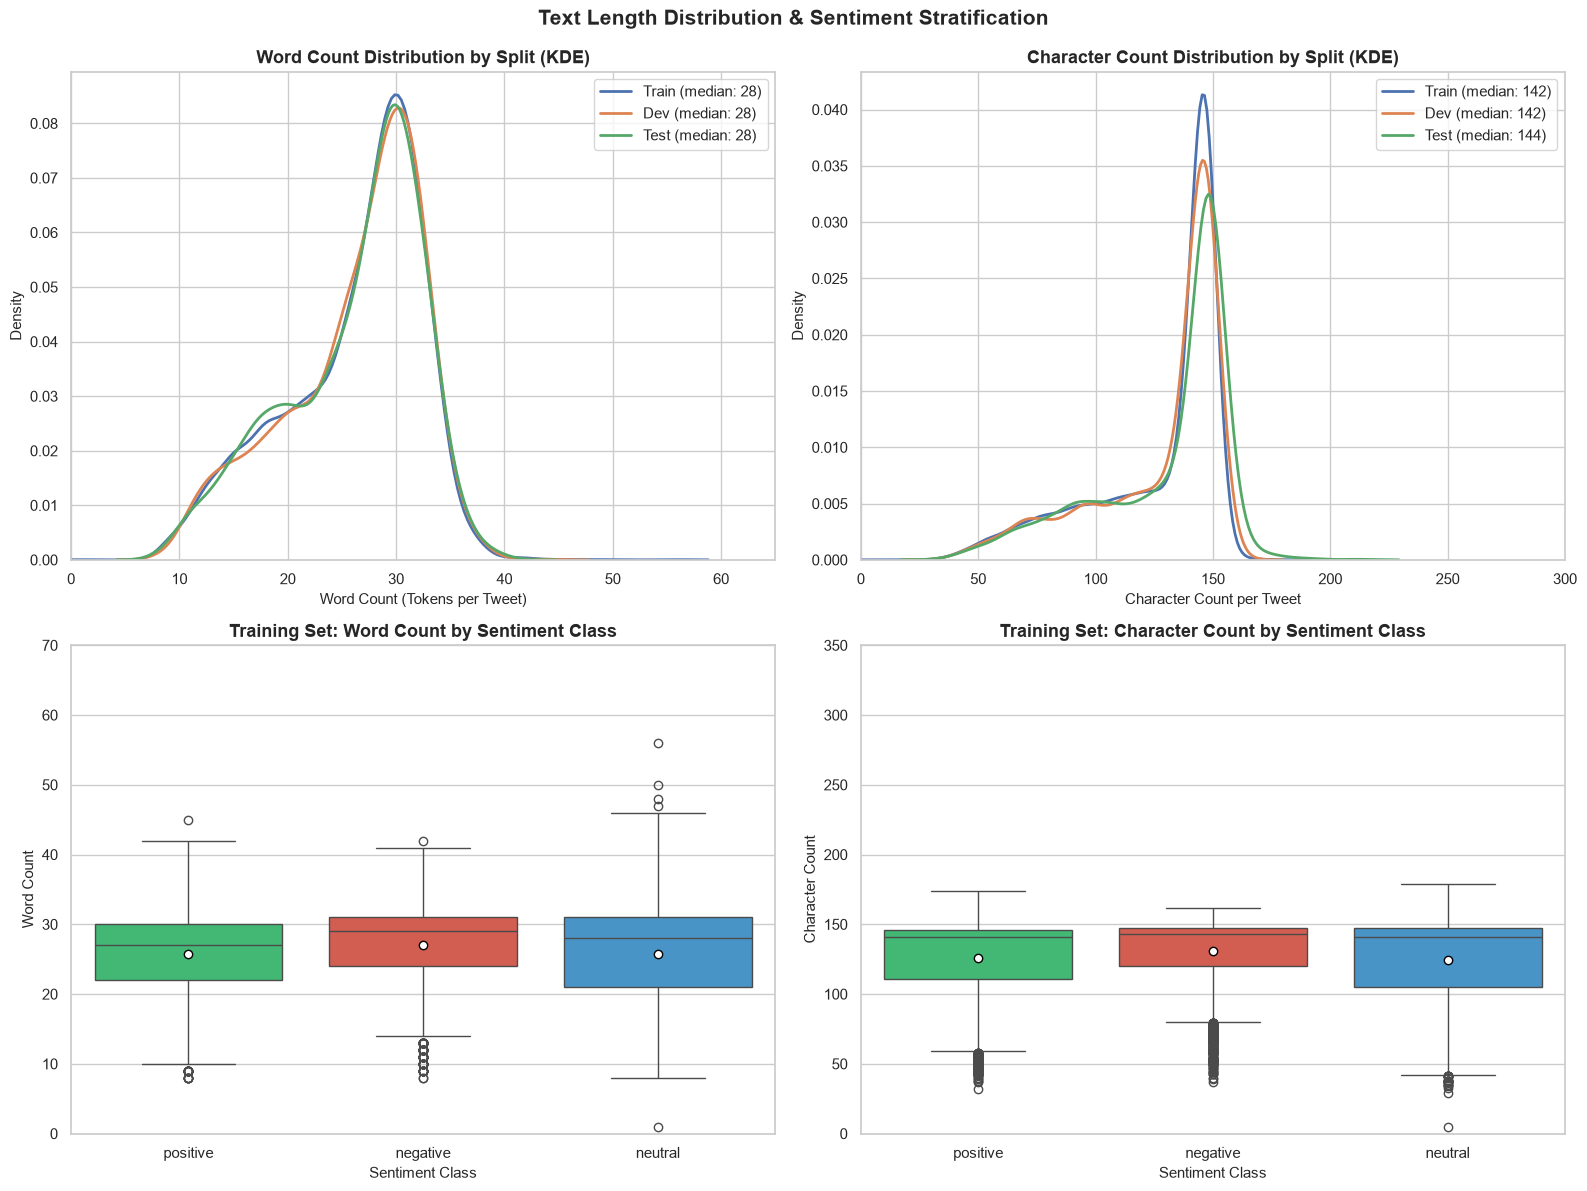

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (a) Word Count Density by Split
ax_wc = axes[0, 0]
for name, df in splits.items():
    sns.kdeplot(df["word_count"], ax=ax_wc, label=f"{name} (median: {df['word_count'].median():.0f})", linewidth=2)
ax_wc.set_title("Word Count Distribution by Split (KDE)", fontsize=13, fontweight="bold")
ax_wc.set_xlabel("Word Count (Tokens per Tweet)", fontsize=11)
ax_wc.set_ylabel("Density", fontsize=11)
ax_wc.set_xlim(0, 65)
ax_wc.legend(frameon=True)

# (b) Character Count Density by Split
ax_cc = axes[0, 1]
for name, df in splits.items():
    sns.kdeplot(df["char_count"], ax=ax_cc, label=f"{name} (median: {df['char_count'].median():.0f})", linewidth=2)
ax_cc.set_title("Character Count Distribution by Split (KDE)", fontsize=13, fontweight="bold")
ax_cc.set_xlabel("Character Count per Tweet", fontsize=11)
ax_cc.set_ylabel("Density", fontsize=11)
ax_cc.set_xlim(0, 300)
ax_cc.legend(frameon=True)

# (c) Word Count Boxplot by Sentiment
ax_box_w = axes[1, 0]
sns.boxplot(
    data=train_df,
    x="sentiment",
    y="word_count",
    hue="sentiment",
    legend=False,
    order=["positive", "negative", "neutral"],
    palette=palette,
    ax=ax_box_w,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
)
ax_box_w.set_title("Training Set: Word Count by Sentiment Class", fontsize=13, fontweight="bold")
ax_box_w.set_xlabel("Sentiment Class", fontsize=11)
ax_box_w.set_ylabel("Word Count", fontsize=11)
ax_box_w.set_ylim(0, 70)

# (d) Character Count Boxplot by Sentiment
ax_box_c = axes[1, 1]
sns.boxplot(
    data=train_df,
    x="sentiment",
    y="char_count",
    hue="sentiment",
    legend=False,
    order=["positive", "negative", "neutral"],
    palette=palette,
    ax=ax_box_c,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
)
ax_box_c.set_title("Training Set: Character Count by Sentiment Class", fontsize=13, fontweight="bold")
ax_box_c.set_xlabel("Sentiment Class", fontsize=11)
ax_box_c.set_ylabel("Character Count", fontsize=11)
ax_box_c.set_ylim(0, 350)

plt.suptitle("Text Length Distribution & Sentiment Stratification", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


## 6. Vocabulary Size & Out-of-Vocabulary (OOV) Rate

In [9]:
train_tokens = [t.lower() for text in train_df["text"] for t in text.split()]
dev_tokens = [t.lower() for text in dev_df["text"] for t in text.split()]
test_tokens = [t.lower() for text in test_df["text"] for t in text.split()]

train_vocab = set(train_tokens)
dev_vocab = set(dev_tokens)
test_vocab = set(test_tokens)
total_vocab = train_vocab | dev_vocab | test_vocab

dev_oov = len(dev_vocab - train_vocab)
test_oov = len(test_vocab - train_vocab)
dev_oov_pct = (dev_oov / len(dev_vocab)) * 100
test_oov_pct = (test_oov / len(test_vocab)) * 100

vocab_df = pd.DataFrame([
    {"Metric": "Total Token Occurrences", "Train": f"{len(train_tokens):,}", "Dev": f"{len(dev_tokens):,}", "Test": f"{len(test_tokens):,}", "Overall Corpus": f"{len(train_tokens)+len(dev_tokens)+len(test_tokens):,}"},
    {"Metric": "Unique Vocabulary Size", "Train": f"{len(train_vocab):,}", "Dev": f"{len(dev_vocab):,}", "Test": f"{len(test_vocab):,}", "Overall Corpus": f"{len(total_vocab):,}"},
    {"Metric": "Out-of-Vocabulary (vs Train)", "Train": "0 (Reference)", "Dev": f"{dev_oov:,} ({dev_oov_pct:.2f}%)", "Test": f"{test_oov:,} ({test_oov_pct:.2f}%)", "Overall Corpus": "N/A"}
]).set_index("Metric")

display(vocab_df)


,Train,Dev,Test,Overall Corpus
Metric,,,,
Total Token Occurrences,"365,528","78,676","78,366","522,570"
Unique Vocabulary Size,"50,181","17,050","16,772","64,476"
Out-of-Vocabulary (vs Train),0 (Reference),"7,405 (43.43%)","7,326 (43.68%)",N/A


## 7. Token Frequencies & Word Distribution

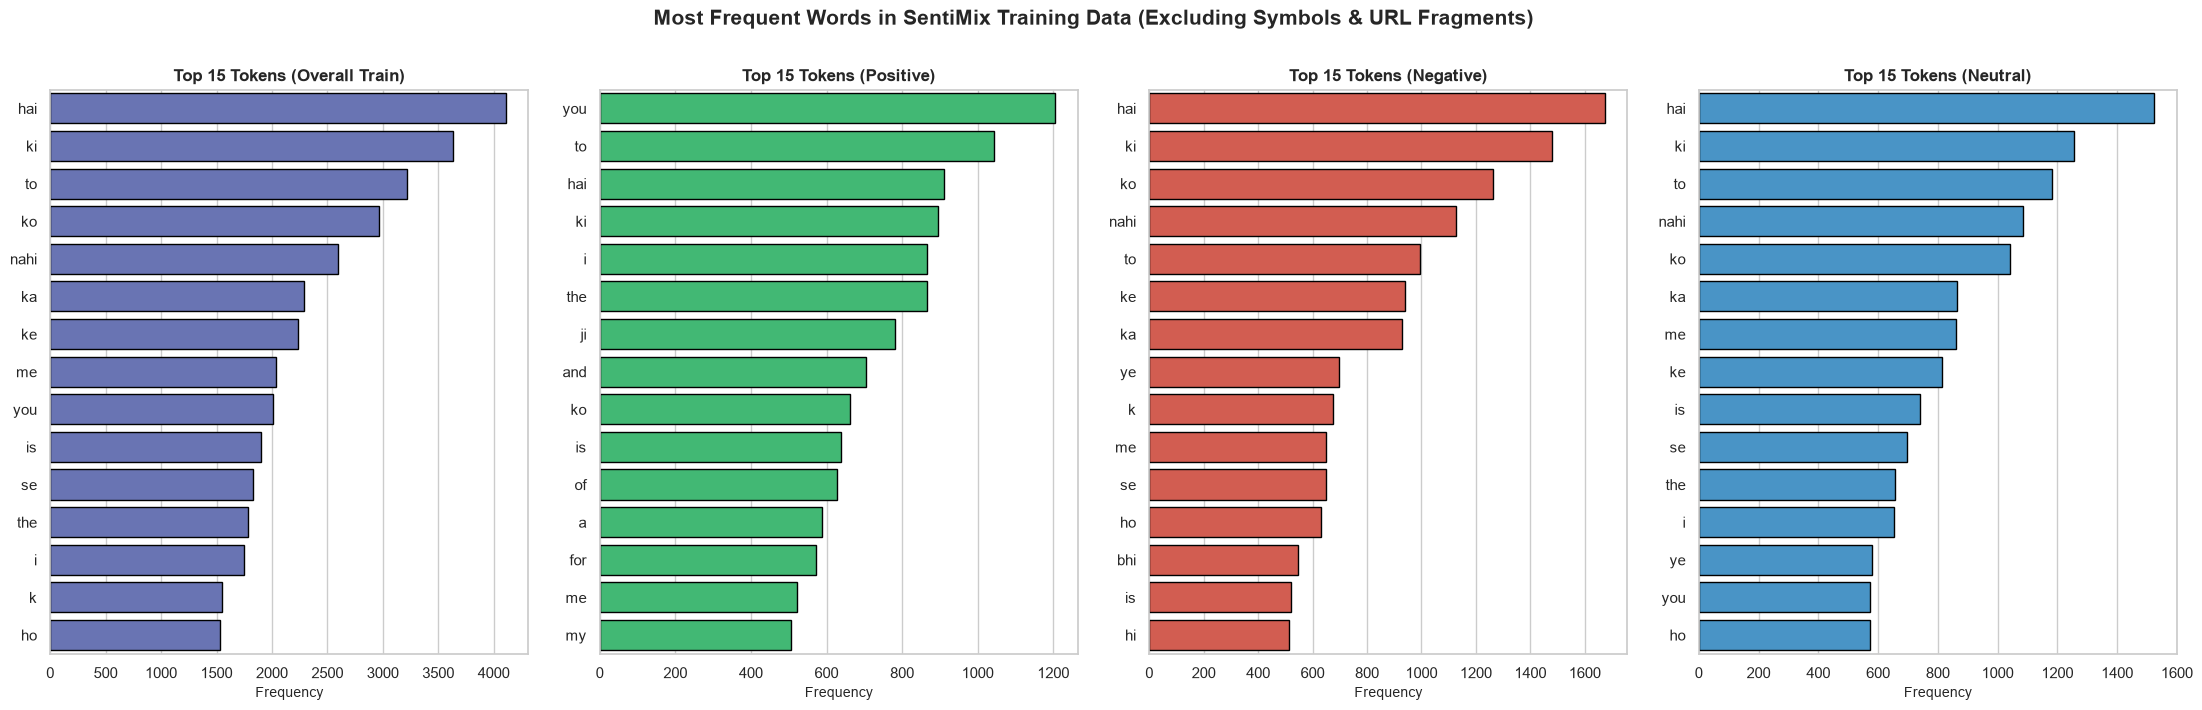

In [10]:
punct_tokens = set(string.punctuation) | {"...", "//", "…", "rt", "http", "https", "t", "co", "tco", "_"}

fig, axes = plt.subplots(1, 4, figsize=(22, 7))

# Overall top 15 words
overall_tokens = [t.lower() for text in train_df["text"] for t in text.split() if t.lower() not in punct_tokens]
top_overall = Counter(overall_tokens).most_common(15)
words, freqs = zip(*top_overall)
sns.barplot(x=list(freqs), y=list(words), ax=axes[0], color="#5c6bc0", edgecolor="black")
axes[0].set_title("Top 15 Tokens (Overall Train)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Frequency", fontsize=10)

# Top words per sentiment class
class_colors = {"positive": "#2ecc71", "negative": "#e74c3c", "neutral": "#3498db"}
for idx, s_class in enumerate(["positive", "negative", "neutral"], 1):
    class_texts = train_df[train_df["sentiment"] == s_class]["text"]
    class_tokens = [t.lower() for text in class_texts for t in text.split() if t.lower() not in punct_tokens]
    top_cls = Counter(class_tokens).most_common(15)
    w, f = zip(*top_cls)
    sns.barplot(x=list(f), y=list(w), ax=axes[idx], color=class_colors[s_class], edgecolor="black")
    axes[idx].set_title(f"Top 15 Tokens ({s_class.capitalize()})", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Frequency", fontsize=10)

plt.suptitle("Most Frequent Words in SentiMix Training Data (Excluding Symbols & URL Fragments)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 8. Characteristics of Hindi-English Code-Mixed Social Media Text

In [11]:
def analyze_features(df):
    tot = len(df)
    n_mentions = df["text"].str.contains(r"@\w+|@\s+\w+", regex=True).sum()
    n_hashtags = df["text"].str.contains(r"#\w+", regex=True).sum()
    n_urls = df["text"].str.contains(r"https?://|https?\s+//|t\.co|tco", regex=True, case=False).sum()
    n_non_ascii = df["text"].apply(lambda t: any(ord(c) > 127 for c in t)).sum()
    n_elong = df["text"].apply(lambda t: bool(re.search(r"([a-zA-Z]){2,}", t))).sum()
    
    return {
        "User Mentions (@)": f"{(n_mentions / tot) * 100:.2f}%",
        "Hashtags (#)": f"{(n_hashtags / tot) * 100:.2f}%",
        "URLs / Links": f"{(n_urls / tot) * 100:.2f}%",
        "Non-ASCII / Emojis": f"{(n_non_ascii / tot) * 100:.2f}%",
        "Character Elongation": f"{(n_elong / tot) * 100:.2f}%"
    }

feature_rows = []
for name, df in splits.items():
    feats = analyze_features(df)
    feats["Split"] = name
    feature_rows.append(feats)

feature_df = pd.DataFrame(feature_rows).set_index("Split")
display(feature_df)


,User Mentions (@),Hashtags (#),URLs / Links,Non-ASCII / Emojis,Character Elongation
Split,,,,,
Train,80.56%,0.21%,55.81%,71.46%,0.00%
Dev,81.03%,0.20%,56.77%,71.13%,0.00%
Test,81.50%,0.30%,53.37%,70.63%,0.00%


## 9. Representative Sentiment Examples

In [12]:
for s_class in ["positive", "negative", "neutral"]:
    print("=" * 80)
    print(f" REPRESENTATIVE EXAMPLES: {s_class.upper()} CLASS")
    print("=" * 80)
    samples = train_df[train_df["sentiment"] == s_class].head(3)
    for i, (_, row) in enumerate(samples.iterrows(), 1):
        print(f"[{i}] UID: {row['uid']}")
        print(f"    Text: {row['text']}\n")


 REPRESENTATIVE EXAMPLES: POSITIVE CLASS
[1] UID: 2512
    Text: @ AmitShah @ narendramodi All India me nrc lagu kare w Kashmir se dhara 370ko khatam kare ham Indian ko apse yahi umid hai

[2] UID: 14356
    Text: @ narendramodi jeet ki dher sari subh kamnaye modi ji asha karta hu jistarah desh ki janta ne khas kar Bihar ki jant … https // t co / XPCzJ7GFqC

[3] UID: 26930
    Text: RT @ Mastani4423509 Tu Safar Mera Tu Hi Meri Manzil .... Tere Bina Guzara Aye DiL Hai Mushkil .... 💘🙈 I LOVE U @ iamsrk ❤ !! https // t . co / vd3 …

 REPRESENTATIVE EXAMPLES: NEGATIVE CLASS
[1] UID: 6648
    Text: @ RahulGandhi television media congress ke liye nhi h . Ye toh aapko pata chal hi gya hoga . Achha hoga ki Congress ke … https // t . co / HmH8M7PTaK

[2] UID: 5840
    Text: @ Fakeionist @ SAMjhotaXpress @ PLiChapel but topi walay babu ki tau new job hougi humey chutti kesay milay gi ? 😭😭😭😭

[3] UID: 37480
    Text: @ TarekFatah Baih tere itjey Kya jalti hai Pakistan se @ TheRealPCB chutiye khel

## 10. Key Insights & Robustness Implications

1. **Balanced Class Distribution**:
   - The dataset has approximately **37.6% Neutral**, **33.1% Positive**, and **29.3% Negative** examples. All three splits mirror this distribution closely.
2. **Compact Sequence Lengths**:
   - Tweets average **~26 words** (median **28 words**, IQR **[22 - 31]**), with 95% of tweets having ≤ 34 words.
3. **High Orthographic & Vocabulary Diversity**:
   - Out-of-vocabulary rate between train and test/dev exceeds **43%**, highlighting significant variation in transliteration (e.g. *nahi* vs *nhi* vs *nahin*).
4. **Rich Noise Perturbation Opportunities**:
   - High prevalence of user handles (80.6%), URLs (55.8%), emojis (71.5%), and phonetic spelling variations makes this corpus ideal for evaluating NLP noise robustness.
